# Gradient boosting regression of cortical bone modulus from chemical composition
E: modulus in GPa

Ca: calcium concentration in gm/gm

Vf: bone volume fraction (1-porosity)

Model: `sklearn.ensemble.GradientBoostingRegressor` — an additive ensemble of shallow regression trees, no physical form assumed

E ≈ F_M(Ca, Vf) = F_0 + ν·[h_1(Ca, Vf) + h_2(Ca, Vf) + … + h_M(Ca, Vf)]

F_0: mean E of the training data; h_m: regression tree fit to the residuals of the previous m−1 trees; ν: learning rate; M: number of trees

Hyperparameters (M, ν, tree depth, min samples per leaf, subsample fraction) are chosen by 5-fold cross-validation on the training data only

Data to be imported is 'bone_composition_modulus_final'

Code is written to split the data into 75% fitting / 25% test (same shuffle and split as the Currey notebook)


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold

DATA = 'bone_composition_modulus_final.csv'
SEED, TEST_FRAC = 0, 0.25

GRID = {'n_estimators': [50, 100, 200, 400],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [1, 2, 3, 4],
        'min_samples_leaf': [1, 5, 10],
        'subsample': [0.7, 1.0]}

def metrics(obs, pred):
    r = obs - pred
    return dict(R2=1 - (r ** 2).sum() / ((obs - obs.mean()) ** 2).sum(),
                RMSE=np.sqrt((r ** 2).mean()), MAE=np.abs(r).mean(), bias=r.mean())

def fit_split(d, seed):
    idx = np.random.default_rng(seed).permutation(len(d))   # shuffle before splitting
    n_test = int(round(TEST_FRAC * len(d)))
    te, tr = d.iloc[idx[:n_test]], d.iloc[idx[n_test:]]
    X = lambda s: np.column_stack([s.Ca_mg_g.values / 1000, s.Vf.values])
    search = GridSearchCV(GradientBoostingRegressor(random_state=seed), GRID,
                          cv=KFold(5, shuffle=True, random_state=seed),
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X(tr), tr.E_GPa.values)                       # tuning uses training data only
    return tr, te, search, X

d = pd.read_csv(DATA).dropna(subset=['Ca_mg_g', 'Vf', 'E_GPa']).reset_index(drop=True)
tr, te, search, X = fit_split(d, SEED)
gbr, p = search.best_estimator_, search.best_params_
pred_tr, pred_te = gbr.predict(X(tr)), gbr.predict(X(te))
m_tr, m_te = metrics(tr.E_GPa.values, pred_tr), metrics(te.E_GPa.values, pred_te)

print(f'Data: {DATA}, n = {len(d)}: train {len(tr)}, test {len(te)}, shuffle seed {SEED}')
for n, v in p.items(): print(f'  {n} = {v}')
print(f'  5-fold CV RMSE = {-search.best_score_:.3f} ± {search.cv_results_["std_test_score"][search.best_index_]:.2g} GPa (training data)')
print(f'  feature importance: Ca = {gbr.feature_importances_[0]:.3f}, Vf = {gbr.feature_importances_[1]:.3f}')
print(pd.DataFrame({'train': m_tr, 'test': m_te}).round(3).to_string())

Data: bone_composition_modulus_final.csv, n = 369: train 277, test 92, shuffle seed 0
  learning_rate = 0.2
  max_depth = 2
  min_samples_leaf = 10
  n_estimators = 50
  subsample = 0.7
  5-fold CV RMSE = 3.999 ± 0.4 GPa (training data)
  feature importance: Ca = 0.663, Vf = 0.337
      train   test
R2    0.835  0.727
RMSE  3.168  4.197
MAE   2.406  3.027
bias  0.078  0.383


# Plotting block

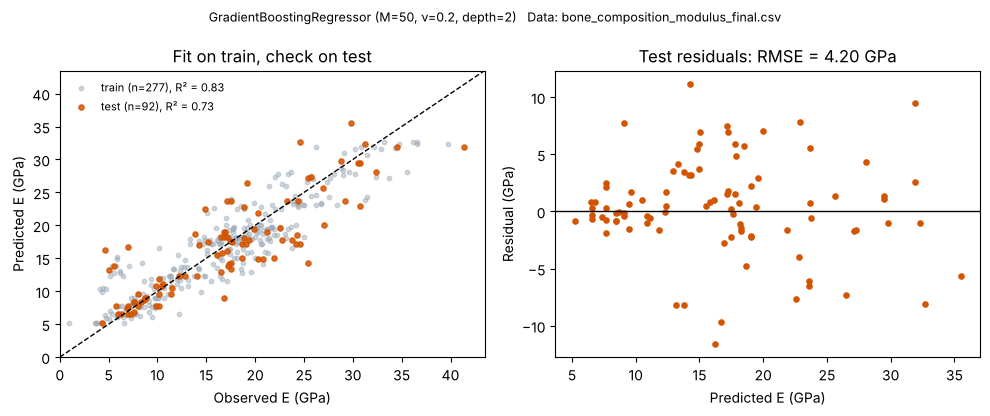

In [2]:
pd.DataFrame({'param': list(p) + ['cv_RMSE_GPa', 'importance_Ca', 'importance_Vf'],
              'value': list(p.values()) + [-search.best_score_, *gbr.feature_importances_]}) \
  .to_csv(f'gbr_split_params.csv', index=False)
pd.concat([tr.assign(set='train', E_pred=pred_tr), te.assign(set='test', E_pred=pred_te)]) \
  .to_csv(f'gbr_split_predictions.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
lim = [0, max(d.E_GPa.max(), pred_tr.max()) * 1.05]
ax[0].scatter(tr.E_GPa, pred_tr, s=10, alpha=.45, color='#9aa7b5', label=f'train (n={len(tr)}), R² = {m_tr["R2"]:.2f}')
ax[0].scatter(te.E_GPa, pred_te, s=14, alpha=.85, color='#d35400', label=f'test (n={len(te)}), R² = {m_te["R2"]:.2f}')
ax[0].plot(lim, lim, 'k--', lw=1); ax[0].legend(frameon=False, fontsize=8)
ax[0].set(xlim=lim, ylim=lim, xlabel='Observed E (GPa)', ylabel='Predicted E (GPa)', title='Fit on train, check on test')
ax[1].scatter(pred_te, te.E_GPa - pred_te, s=14, color='#d35400'); ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='Predicted E (GPa)', ylabel='Residual (GPa)', title=f'Test residuals: RMSE = {m_te["RMSE"]:.2f} GPa')
fig.suptitle(f'GradientBoostingRegressor (M={p["n_estimators"]}, ν={p["learning_rate"]}, depth={p["max_depth"]})   Data: {DATA}', fontsize=9)
fig.tight_layout(); fig.savefig(f'gbr_split.png', dpi=150)
plt.show()